# Ejercicio k-Nearest Neighbor

## App Reviews
En este ejercicio vas a trabajar con una base de datos de reviews de una aplicación. Entre los datos podemos encontrar el texto de la review, las estrellas, así como el sentimiento del comentario (si es algo bueno o malo).

El objetivo es montar un algoritmo de clasificación que prediga el rating, en función del sentimiento del comentario y la cantidad de palabras empleadas en el mismo. Para ello tendrás que utilizar un algoritmo de tipo KNN.

## Importamos las librerías que vamos a utilizar

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Leemos nuestro archivo de entrada `reviews_sentiment`

Para facilitar el ejercicio, las columnas que utilizaremos serán: wordcount con la cantidad de palabras utilizadas y sentimentValue con un valor entre -4 y 4 que indica si el comentario fue valorado como positivo o negativo

Nuestras etiquetas, serán las estrellas que dieron los usuarios a la app, que son valores discretos del 1 al 5

In [2]:
df = pd.read_csv('./data/reviews_sentiment.csv', sep=';')

In [3]:
df.head()

,Review Title,Review Text,wordcount,titleSentiment,textSentiment,Star Rating,sentimentValue
0,Sin conexión,Hola desde hace algo más de un mes me pone sin...,23,negative,negative,1,-0.486389
1,faltan cosas,Han mejorado la apariencia pero no,20,negative,negative,1,-0.586187
2,Es muy buena lo recomiendo,Andres e puto amoooo,4,NaN,negative,1,-0.602240
3,Version antigua,Me gustana mas la version anterior esta es mas...,17,NaN,negative,1,-0.616271
4,Esta bien,Sin ser la biblia.... Esta bien,6,negative,negative,1,-0.651784


In [4]:
df.info()   #solo tengo nulos en 'titleSentiment', pero el ejercicio no me manda usar esa vble

<class 'pandas.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Review Title    257 non-null    str    
 1   Review Text     257 non-null    str    
 2   wordcount       257 non-null    int64  
 3   titleSentiment  231 non-null    str    
 4   textSentiment   257 non-null    str    
 5   Star Rating     257 non-null    int64  
 6   sentimentValue  257 non-null    float64
dtypes: float64(1), int64(2), str(4)
memory usage: 14.2 KB


In [5]:
df.describe()   #'wordcount' y 'sentimentValue' son las vbles que me dice el ejercicio que useson enteros y floats respectivamente

,wordcount,Star Rating,sentimentValue
count,257.000000,257.000000,257.000000
mean,11.501946,3.420233,0.383849
std,13.159812,1.409531,0.897987
min,1.000000,1.000000,-2.276469
25%,3.000000,3.000000,-0.108144
50%,7.000000,3.000000,0.264091
75%,16.000000,5.000000,0.808384
max,103.000000,5.000000,3.264579


## Rápidas visualizaciones y análisis
Al menos realiza un análisis univariante y representa la distribución del rating. Realiza otras visualizaciones para ver la relación de tus datos.

In [6]:
#El anáslisis univariante lo hice arriva

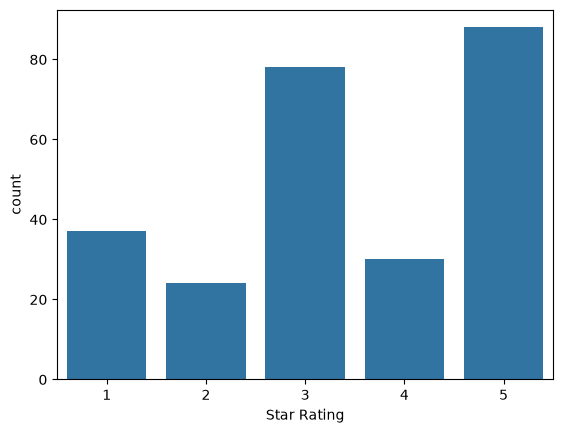

In [7]:
#Represento la distribución del rating
sns.countplot(data=df, x='Star Rating')
plt.show()

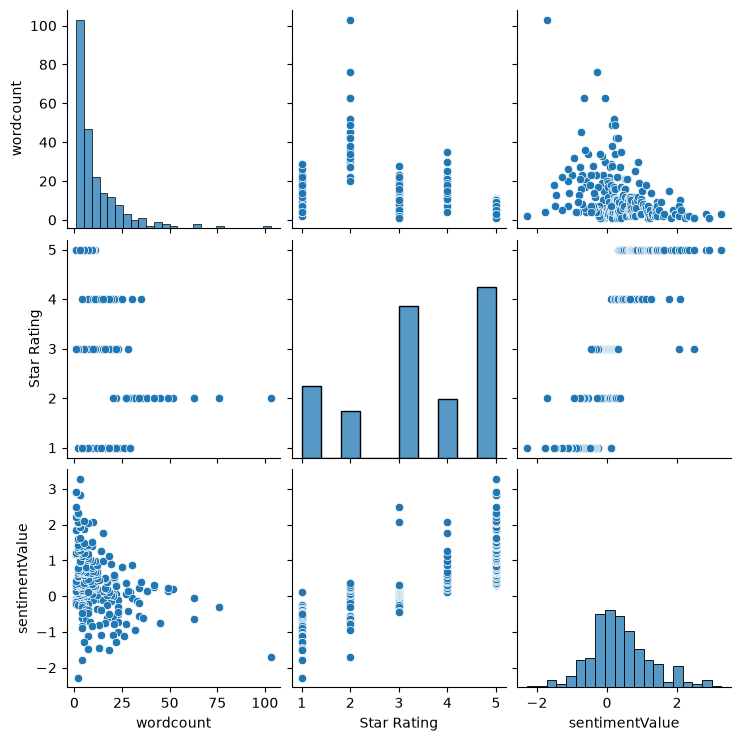

In [8]:
sns.pairplot(df)
plt.show()

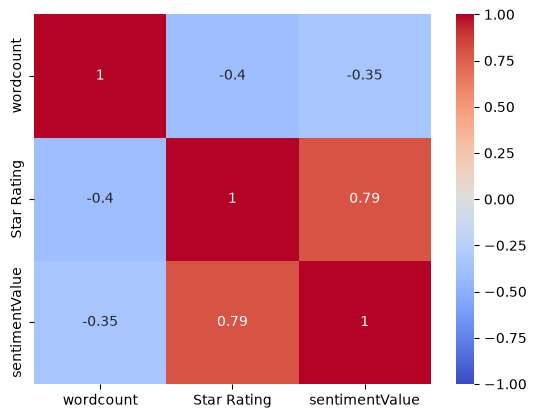

In [9]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", vmin=-1);

<Axes: xlabel='wordcount', ylabel='sentimentValue'>

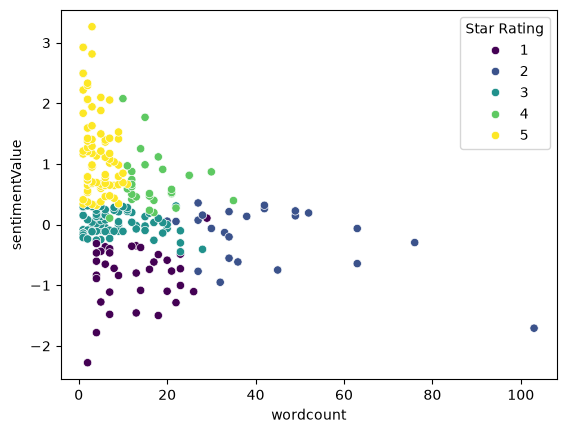

In [10]:
#Hago un scactter plot de las 3 vbles
sns.scatterplot(data=df, x='wordcount', y='sentimentValue', hue='Star Rating', palette='viridis')

## Preparamos el dataset
Divide en train/test y escala las features en el rango [0, 1].

In [11]:
#Divido entre train/test

from sklearn.model_selection import train_test_split

X = df[['wordcount', 'sentimentValue']]
y = df['Star Rating']

#Sigo el criterio habitual 80% tarin y 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify=y)   #mantiene exactamente la misma proporción de clases en la vble y

In [12]:
#Escalo. Como en el enunciado me piden que todos los valores queden dentro del rango [0, 1] tengo que usar MinMaxScaler

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Creamos el Modelo
Entrena con un KNN y evalúa el error en train y en test

In [13]:
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

#Entreno el modelo
knn_clf = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
knn_clf.fit(X_train_scaled, y_train)

#Predicciones en train y test
y_train_pred_knn = knn_clf.predict(X_train_scaled)
y_test_pred_knn = knn_clf.predict(X_test_scaled)

## Evalúa tu modelo

In [14]:
from sklearn.metrics import accuracy_score

#Evalúo el accuray
acc_train_knn = accuracy_score(y_train, y_train_pred_knn)
acc_test_knn = accuracy_score(y_test, y_test_pred_knn)

print(f'Accuracy Train: {acc_train_knn:.4f}')
print(f'Accuracy Test: {acc_test_knn:.4f}')

Accuracy Train: 0.9073
Accuracy Test: 0.9038


In [ ]:
#El accuracy del train y el test es aprox 0.9 en ambos, por lo que parece que generaliza bien sin overfitting

In [15]:
from sklearn.metrics import classification_report

print(classification_report(y_train, y_train_pred_knn))   #Support es cuantos datos tengo de cada uno, como puse el stratify son proporcionales

              precision    recall  f1-score   support

           1       0.93      0.93      0.93        30
           2       0.85      0.89      0.87        19
           3       0.88      0.95      0.91        62
           4       0.88      0.62      0.73        24
           5       0.94      0.96      0.95        70

    accuracy                           0.91       205
   macro avg       0.90      0.87      0.88       205
weighted avg       0.91      0.91      0.90       205



In [16]:
print(classification_report(y_test, y_test_pred_knn))

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         7
           2       1.00      0.80      0.89         5
           3       0.83      0.94      0.88        16
           4       0.83      0.83      0.83         6
           5       0.94      0.89      0.91        18

    accuracy                           0.90        52
   macro avg       0.92      0.89      0.90        52
weighted avg       0.91      0.90      0.90        52



<Axes: >

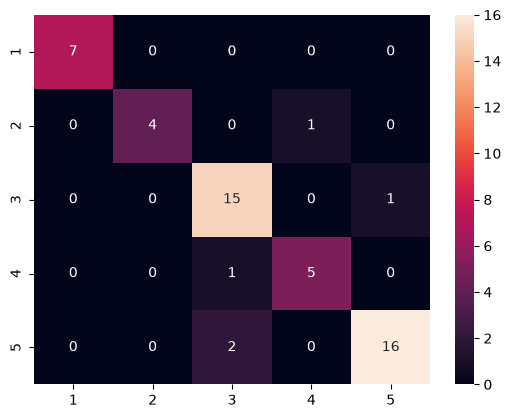

In [22]:
#Matriz de confusión

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_pred_knn)

sns.heatmap(cm, annot=True, xticklabels=[1,2,3,4,5], yticklabels=[1,2,3,4,5])

## ¿Cómo obtener el mejor valor de k? Crea y evalúa nuevos modelos
¿Qué valor de k maximiza el accuracy? Representa todas las iteraciones en un scatterplot -> k vs accuracy

In [23]:
#Itero sobre un rango de valores de k, bucle for
k = range(1, 51)
scores = []

for i in k:
    knn = KNeighborsClassifier(n_neighbors=i, metric='euclidean')
    knn.fit(X_train_scaled, y_train)
    scores.append(knn.score(X_test_scaled, y_test))

#Calculo el mejor
mejor_k = k[np.argmax(scores)]   #argmax para obtener el k (índice de la lista) con mayor score
mejor_score = max(scores)
print(f'El mejor valor de K es {mejor_k}, que maximiza el accuracy con un valor de {mejor_score:.4f}')

El mejor valor de K es 3, que maximiza el accuracy con un valor de 0.9038


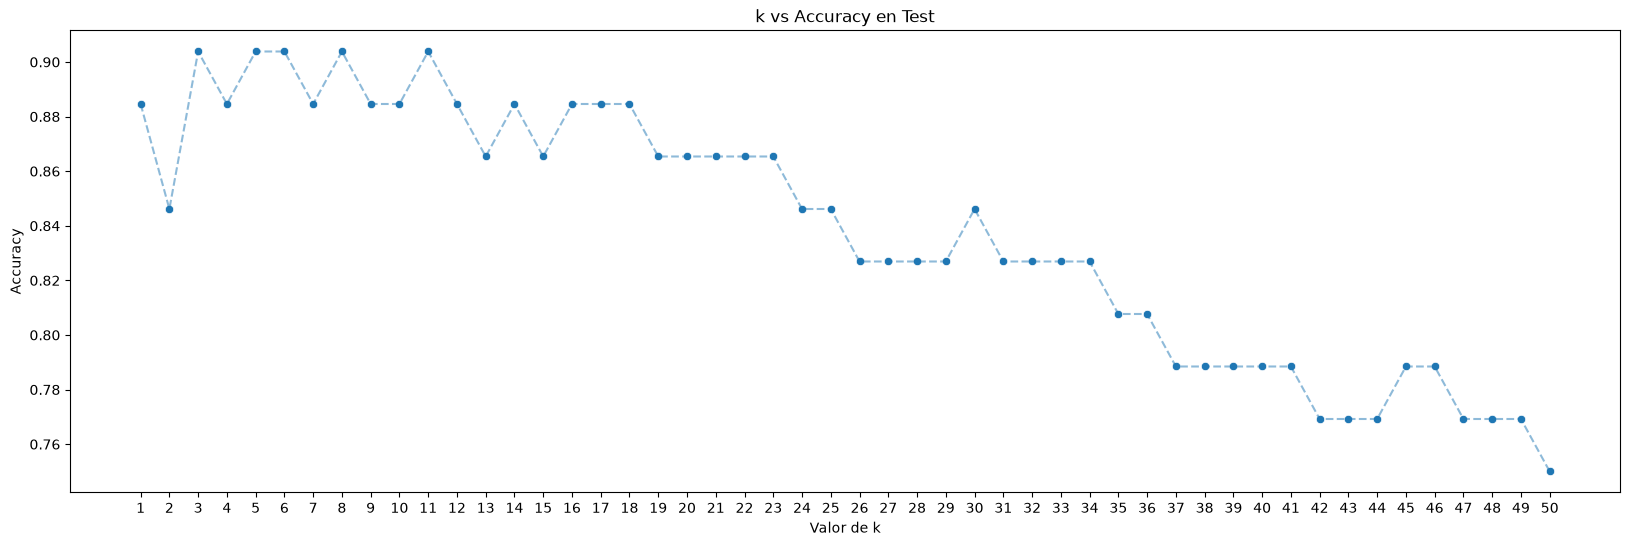

In [32]:
#Dibujo el scatterplot
plt.figure(figsize=(20, 6))
sns.scatterplot(x=list(k), y=scores)
plt.plot(k, scores, linestyle='--', alpha=0.5) 
plt.title('k vs Accuracy en Test')
plt.xlabel('Valor de k')
plt.ylabel('Accuracy')
plt.xticks(k)
plt.show()

## Predice con nuevos datos.
Ejemplo: supongamos que nos llega una review de 5 palabras y sentimiento 1

In [35]:
#creo nuevo dato con 5 palabras y sentimiento 1
nueva_review = pd.DataFrame({'wordcount': [5], 'sentimentValue': [1]})

#Escalo!!!! ya definí arriba que el scaler era MinMaxScaler
nueva_review_scaled = scaler.transform(nueva_review)

#Predigo con el mejor modelo que obtuve en el apartado anterior
mejor_modelo_knn = KNeighborsClassifier(n_neighbors=mejor_k, metric='euclidean')
mejor_modelo_knn.fit(X_train_scaled, y_train)
prediccion = mejor_modelo_knn.predict(nueva_review_scaled)
print(f'Si tengo una review con 5 palabras y un sentimiento de 1, el rating previsiblemente sería: {prediccion}')

Si tengo una review con 5 palabras y un sentimiento de 1, el rating previsiblemente sería: [5]
